<a href="https://colab.research.google.com/github/s61711299-sketch/MSSP6070/blob/main/Week_13_Financial_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from google.colab import userdata
import os
import subprocess

owner = 's61711299-sketch' # Replace with the GitHub repository owner
repository = 'MSSP6070' # Replace with the GitHub repository name

!git clone https://github.com/{owner}/{repository}.git
os.chdir(repository)


Cloning into 'MSSP6070'...
remote: Enumerating objects: 331, done.
remote: Counting objects: 100% (152/152), done.
remote: Compressing objects: 100% (151/151), done.
remote: Total 331 (delta 72), reused 0 (delta 0), pack-reused 179 (from 1)
Receiving objects: 100% (331/331), 9.54 MiB | 17.97 MiB/s, done.
Resolving deltas: 100% (145/145), done.


In [5]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.float_format', lambda x: '%.2f' % x)

#Python for retrieving, analyzing, and comparing stock prices

In [8]:
#Set up notebook by running my own module.
#the file contatins:
#import pandas as pd
#import seaborn as sns
#import numpy as np
#import matplotlib.pyplot as plt
#pd.set_option('display.float_format', lambda x: '%.2f' % x)
runfile ('/content/MSSP6070/week13/Week 13 Financial Data.ipynb')

In [9]:
!pip install yfinance --upgrade --no-cache-dir

  Attempting uninstall: yfinance
    Found existing installation: yfinance 0.2.66
    Uninstalling yfinance-0.2.66:
      Successfully uninstalled yfinance-0.2.66


In [10]:
from pandas_datareader import data as pdr
import yfinance as yf
import datetime

In [11]:
Amazon = yf.Ticker("AMZN")
print(Amazon.info['sector'])
print(Amazon.info['trailingPE'])
print(Amazon.info['beta'])

Consumer Cyclical
20.395311
1.503


In [12]:
for key, value in Amazon.info.items():
    print(key, ":", value)

address1 : 410 Terry Avenue North
city : Seattle
state : WA
zip : 98109-5210
country : United States
phone : 206 266 1000
website : https://www.amazon.com
industry : Internet Retail
industryKey : internet-retail
industryDisp : Internet Retail
sector : Consumer Cyclical
sectorKey : consumer-cyclical
sectorDisp : Consumer Cyclical
longBusinessSummary : Amazon.com, Inc. engages in the retail sale of consumer products, advertising, and subscriptions service through online and physical stores in North America and internationally. The company operates through three segments: North America, International, and Amazon Web Services (AWS). It also manufactures and sells electronic devices, including Kindle, fire tablets, fire TVs, echo, ring, blink, and eero; and develops and produces media content. In addition, the company offers programs that enable sellers to sell their products in its stores; and programs that allow authors, independent publishers, musicians, filmmakers, Twitch streamers, ski

In [13]:
print(Amazon.history(period="max"))

                            Open   High    Low  Close      Volume  Dividends  \
Date                                                                           
1997-05-15 00:00:00-04:00   0.12   0.12   0.10   0.10  1443120000       0.00   
1997-05-16 00:00:00-04:00   0.10   0.10   0.09   0.09   294000000       0.00   
1997-05-19 00:00:00-04:00   0.09   0.09   0.08   0.09   122136000       0.00   
1997-05-20 00:00:00-04:00   0.09   0.09   0.08   0.08   109344000       0.00   
1997-05-21 00:00:00-04:00   0.08   0.08   0.07   0.07   377064000       0.00   
...                          ...    ...    ...    ...         ...        ...   
2026-11-18 00:00:00-05:00 259.81 268.29 259.51 267.74    41289500       0.00   
2026-11-19 00:00:00-05:00 272.56 274.00 256.75 257.37    53117900       0.00   
2026-11-20 00:00:00-05:00 253.48 259.97 245.31 246.82    74362600       0.00   
2026-11-23 00:00:00-05:00 260.26 262.48 251.25 255.39    53277400       0.00   
2026-11-24 00:00:00-05:00 252.54 255.56 

In [14]:
print(Amazon.history(start='2023-01-01', end='2023-12-31'))

                            Open   High    Low  Close    Volume  Dividends  \
Date                                                                         
2023-01-03 00:00:00-05:00  85.46  86.96  84.21  85.82  76706000       0.00   
2023-01-04 00:00:00-05:00  86.55  86.98  83.36  85.14  68885100       0.00   
2023-01-05 00:00:00-05:00  85.33  85.42  83.07  83.12  67930800       0.00   
2023-01-06 00:00:00-05:00  83.03  86.40  81.43  86.08  83303400       0.00   
2023-01-09 00:00:00-05:00  87.46  89.48  87.08  87.36  65266100       0.00   
...                          ...    ...    ...    ...       ...        ...   
2023-12-22 00:00:00-05:00 153.77 154.35 152.71 153.42  29514100       0.00   
2023-12-26 00:00:00-05:00 153.56 153.98 153.03 153.41  25067200       0.00   
2023-12-27 00:00:00-05:00 153.56 154.78 153.12 153.34  31434700       0.00   
2023-12-28 00:00:00-05:00 153.72 154.08 152.95 153.38  27057000       0.00   
2023-12-29 00:00:00-05:00 153.10 153.89 151.03 151.94  39823200 


In the context of downloading data from Yahoo Finance using the yfinance library, the period parameter defines the range of data to download and can have the following values:

*    1d, 5d: data for the past 1 or 5 days

*   1mo, 3mo, 6mo: data for the past 1, 3, or 6 months
*   1y, 2y, 5y, 10y, ytd: data for the past 1, 2, 5, or 10 years, or year to date.


*   max: data for the maximum available period.


These values allow you to specify the time frame for which you want to retrieve historical data for a given stock.

In [15]:

# startDate , as per our convenience we can modify
startDate = datetime.datetime(2019, 5, 31)

# endDate , as per our convenience we can modify
endDate = datetime.datetime(2021, 1, 30)

# pass the parameters as the taken dates for start and end
print(Amazon.history(period='1mo'))

                            Open   High    Low  Close     Volume  Dividends  \
Date                                                                          
2026-10-26 00:00:00-04:00 249.47 250.79 247.23 249.09   32696400       0.00   
2026-10-27 00:00:00-04:00 250.43 254.68 248.71 253.10   34477800       0.00   
2026-10-28 00:00:00-04:00 253.00 255.36 251.98 254.60   34915900       0.00   
2026-10-29 00:00:00-04:00 246.95 249.14 241.24 243.79   85234400       0.00   
2026-10-30 00:00:00-04:00 232.54 241.55 229.36 240.35  104894700       0.00   
2026-11-02 00:00:00-05:00 243.01 253.81 242.28 245.63   58348000       0.00   
2026-11-03 00:00:00-05:00 248.59 252.45 245.88 250.69   37853500       0.00   
2026-11-04 00:00:00-05:00 264.82 271.49 263.85 266.03   93162200       0.00   
2026-11-05 00:00:00-05:00 271.43 273.23 252.27 260.21   85796800       0.00   
2026-11-06 00:00:00-05:00 259.81 264.18 258.53 259.30   42571500       0.00   
2026-11-09 00:00:00-05:00 269.32 275.34 266.91 266.9

In [16]:
df = pd.DataFrame(Amazon.history(start=startDate,end=endDate))
df

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2019-05-31 00:00:00-04:00,89.50,89.78,88.64,88.75,92376000,0.00,0.00
2019-06-03 00:00:00-04:00,88.00,88.31,83.60,84.63,181974000,0.00,0.00
2019-06-04 00:00:00-04:00,84.96,86.54,84.04,86.48,113582000,0.00,0.00
2019-06-05 00:00:00-04:00,87.48,87.60,85.76,86.93,84796000,0.00,0.00
2019-06-06 00:00:00-04:00,86.89,88.00,86.31,87.72,73786000,0.00,0.00
...,...,...,...,...,...,...,...
2021-01-25 00:00:00-05:00,166.43,168.19,162.16,164.70,74996000,0.00,0.00
2021-01-26 00:00:00-05:00,164.82,166.90,164.14,166.31,59104000,0.00,0.00
2021-01-27 00:00:00-05:00,167.07,167.33,160.35,161.63,93204000,0.00,0.00


#Task 1: Read into seperate data frame the following tickers: Apple, Facebook, Google, and Netflix; use Yahoo finance.

In [22]:
startDate = datetime.datetime(2023, 1, 1)
endDate = datetime.datetime(2023, 12, 31)
apple_ticker = yf.Ticker("AAPL")
df_apple = pd.DataFrame(apple_ticker.history(start=startDate, end=endDate))
print("--- Apple (AAPL) ---")
display(df_apple.head(5))

--- Apple (AAPL) ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-01-03 00:00:00-05:00,127.90,128.51,121.90,122.78,112117500,0.00,0.00
2023-01-04 00:00:00-05:00,124.57,126.31,122.79,124.05,89113600,0.00,0.00
2023-01-05 00:00:00-05:00,124.81,125.43,122.48,122.73,80962700,0.00,0.00
2023-01-06 00:00:00-05:00,123.71,127.91,122.61,127.25,87754700,0.00,0.00
2023-01-09 00:00:00-05:00,128.08,130.97,127.52,127.77,70790800,0.00,0.00


In [23]:
facebook_ticker = yf.Ticker("META")
df_facebook = pd.DataFrame(facebook_ticker.history(start=startDate, end=endDate))
print("\n--- Facebook (META) ---")
display(df_facebook.head(5))


--- Facebook (META) ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-01-03 00:00:00-05:00,121.65,125.17,121.12,123.56,35528500,0.00,0.00
2023-01-04 00:00:00-05:00,126.17,127.83,124.66,126.16,32397100,0.00,0.00
2023-01-05 00:00:00-05:00,124.93,127.30,123.36,125.74,25447100,0.00,0.00
2023-01-06 00:00:00-05:00,127.75,129.09,124.84,128.79,27584500,0.00,0.00
2023-01-09 00:00:00-05:00,129.92,131.69,128.05,128.24,26649100,0.00,0.00


In [24]:
google_ticker = yf.Ticker("GOOGL")
df_google = pd.DataFrame(google_ticker.history(start=startDate, end=endDate))
print("\n--- Google (GOOGL) ---")
display(df_google.head(5))


--- Google (GOOGL) ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-01-03 00:00:00-05:00,88.75,90.19,87.69,88.28,28131200,0.00,0.00
2023-01-04 00:00:00-05:00,89.50,89.80,86.45,87.25,34854800,0.00,0.00
2023-01-05 00:00:00-05:00,86.65,86.74,85.09,85.39,27194400,0.00,0.00
2023-01-06 00:00:00-05:00,85.97,86.86,84.06,86.52,41381500,0.00,0.00
2023-01-09 00:00:00-05:00,87.53,89.20,87.03,87.19,29003900,0.00,0.00


In [25]:
netflix_ticker = yf.Ticker("NFLX")
df_netflix = pd.DataFrame(netflix_ticker.history(start=startDate, end=endDate))
print("\n--- Netflix (NFLX) ---")
display(df_netflix.head(5))


--- Netflix (NFLX) ---


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2023-01-03 00:00:00-05:00,29.81,29.84,28.87,29.50,67640000,0.00,0.00
2023-01-04 00:00:00-05:00,29.82,31.11,29.55,30.94,93451000,0.00,0.00
2023-01-05 00:00:00-05:00,30.70,31.42,30.45,30.97,83284000,0.00,0.00
2023-01-06 00:00:00-05:00,31.16,31.68,30.37,31.56,89598000,0.00,0.00
2023-01-09 00:00:00-05:00,31.68,32.17,31.32,31.52,67666000,0.00,0.00


#Task 2:  Join the individual stock data frames into a single data frame.

In [27]:
combined_full_df = pd.concat([df_apple, df_facebook, df_google, df_netflix],
                             axis=1,
                             keys=['Apple', 'Facebook', 'Google', 'Netflix'])
display(combined_full_df.head())

Apple                                            \
                            Open   High    Low  Close     Volume Dividends   
Date                                                                         
2023-01-03 00:00:00-05:00 127.90 128.51 121.90 122.78  112117500      0.00   
2023-01-04 00:00:00-05:00 124.57 126.31 122.79 124.05   89113600      0.00   
2023-01-05 00:00:00-05:00 124.81 125.43 122.48 122.73   80962700      0.00   
2023-01-06 00:00:00-05:00 123.71 127.91 122.61 127.25   87754700      0.00   
2023-01-09 00:00:00-05:00 128.08 130.97 127.52 127.77   70790800      0.00   

                                       Facebook                ...    Google  \
                          Stock Splits     Open   High    Low  ...    Volume   
Date                                                           ...             
2023-01-03 00:00:00-05:00         0.00   121.65 125.17 121.12  ...  28131200   
2023-01-04 00:00:00-05:00         0.00   126.17 127.83 124.66  ...  34854800   
2023-01-05 00:00:00-05:00         0.00   124.93 127.30 123.36  ...  27194400   
2023-01-06 00:00:00-05:00         0.00   127.75 129.09 124.84  ...  41381500   
2023-01-09 00:00:00-05:00         0.00   129.92 131.69 128.05  ...  29003900   

                                                 Netflix                    \
                          Dividends Stock Splits    Open  High   Low Close   
Date                                                                         
2023-01-03 00:00:00-05:00      0.00         0.00   29.81 29.84 28.87 29.50   
2023-01-04 00:00:00-05:00      0.00         0.00   29.82 31.11 29.55 30.94   
2023-01-05 00:00:00-05:00      0.00         0.00   30.70 31.42 30.45 30.97   
2023-01-06 00:00:00-05:00      0.00         0.00   31.16 31.68 30.37 31.56   
2023-01-09 00:00:00-05:00      0.00         0.00   31.68 32.17 31.32 31.52   

                                                            
                             Volume Dividends Stock Splits  
Date                                                        
2023-01-03 00:00:00-05:00  67640000      0.00         0.00  
2023-01-04 00:00:00-05:00  93451000      0.00         0.00  
2023-01-05 00:00:00-05:00  83284000      0.00         0.00  
2023-01-06 00:00:00-05:00  89598000      0.00         0.00  
2023-01-09 00:00:00-05:00  67666000      0.00         0.00  

[5 rows x 28 columns]

# Task 3: Create a visualization of the following financial metrics for each stock:  quickRatio, currentRatio, totalRevenue, debtToEquity, revenuePerShare, returnOnAssets, returnOnEquity, grossProfits


/tmp/ipykernel_580/3923971565.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plot_data.index, y=plot_data.values, ax=axes[i], palette='viridis')
/tmp/ipykernel_580/3923971565.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plot_data.index, y=plot_data.values, ax=axes[i], palette='viridis')
/tmp/ipykernel_580/3923971565.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=plot_data.index, y=plot_data.values, ax=axes[i], palette='viridis')
/tmp/ipykernel_580/3923971565.py:23: FutureWarning: 

Passing `palette` without assignin

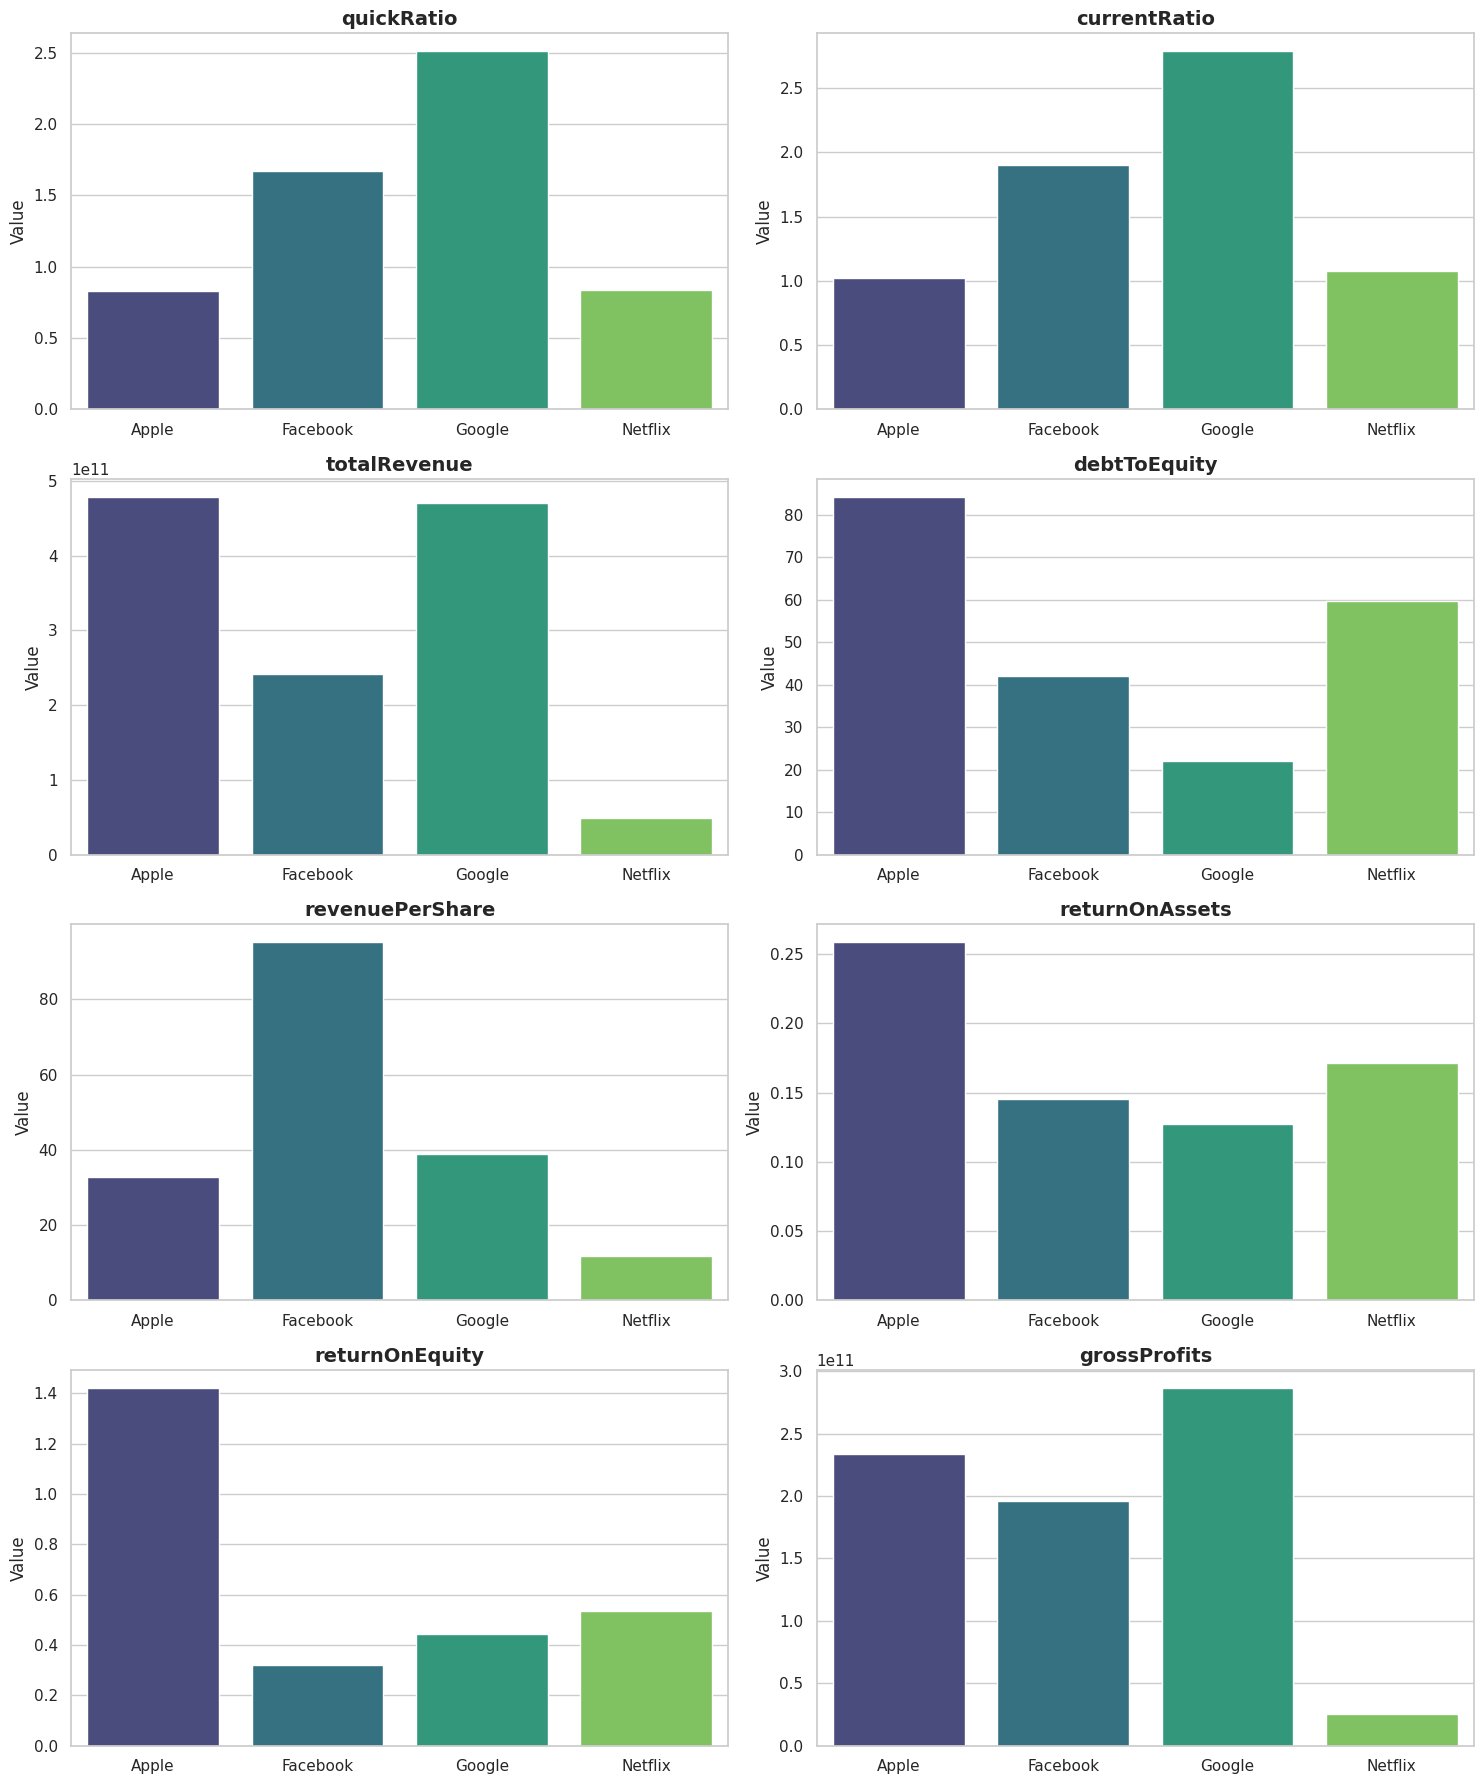

In [33]:
tickers = {
    'Apple': 'AAPL',
    'Facebook': 'META',
    'Google': 'GOOGL',
    'Netflix': 'NFLX'
}
metrics = [
    'quickRatio', 'currentRatio', 'totalRevenue', 'debtToEquity',
    'revenuePerShare', 'returnOnAssets', 'returnOnEquity', 'grossProfits'
]
data = {}
for company, ticker in tickers.items():
    stock = yf.Ticker(ticker)
    info = stock.info
    data[company] = {m: info.get(m, None) for m in metrics}
metrics_df = pd.DataFrame(data)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 18))
axes = axes.flatten()
for i, metric in enumerate(metrics):
    plot_data = metrics_df.loc[metric]

    sns.barplot(x=plot_data.index, y=plot_data.values, ax=axes[i], palette='viridis')

    axes[i].set_title(f'{metric}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Value')
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

#Task 4: Create a single boxplot for the Closing price for each stock.


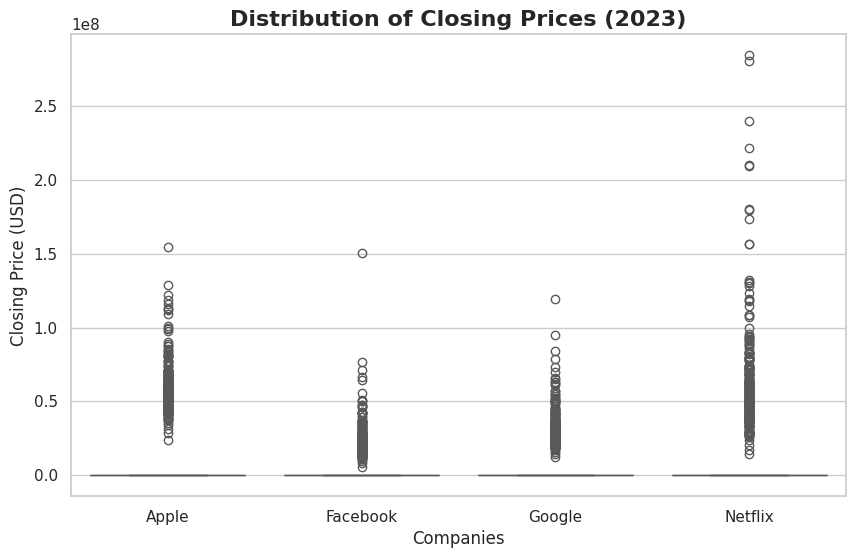

In [35]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_full_df, palette="Set2")
plt.title('Distribution of Closing Prices (2023)', fontsize=16, fontweight='bold')
plt.ylabel('Closing Price (USD)', fontsize=12)
plt.xlabel('Companies', fontsize=12)
plt.show()

# Task 5: Create a daily trading volume visualization for the year 2023 for each stock.


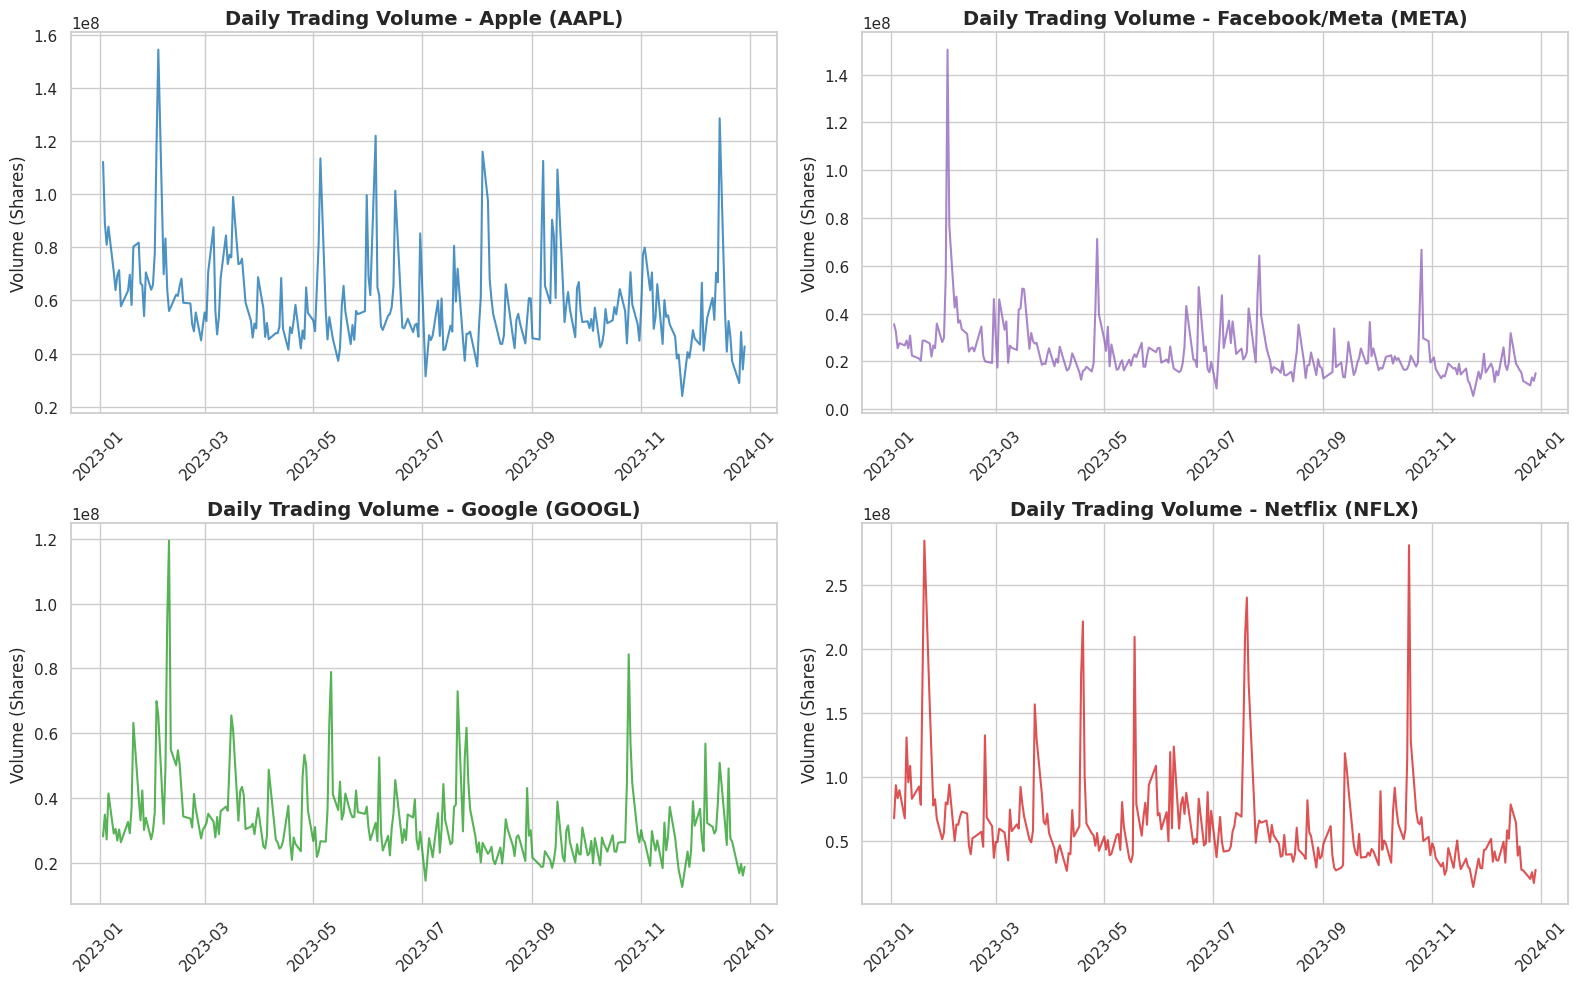

In [37]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10))
axes = axes.flatten()
dfs = [df_apple, df_facebook, df_google, df_netflix]
titles = ['Apple (AAPL)', 'Facebook/Meta (META)', 'Google (GOOGL)', 'Netflix (NFLX)']
colors = ['#1f77b4', '#9467bd', '#2ca02c', '#d62728']
for i in range(4):
    axes[i].plot(dfs[i].index, dfs[i]['Volume'], color=colors[i], linewidth=1.5, alpha=0.8)
    axes[i].set_title(f'Daily Trading Volume - {titles[i]}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('Volume (Shares)', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

#Task 6: Save the combined stock file with the ticker symbols to a CSV file in you Google directory.  Upload the Jupyter Notebook to the assignment in Canvas.

In [41]:
from google.colab import drive
drive.mount('/content/drive')
combined_full_df.to_csv('/content/drive/MyDrive/combined_stock_data.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
